<a href="https://colab.research.google.com/github/Skulfre/Machine-Learning/blob/main/pytorch_workflow_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
from torch import nn
import matplotlib.pyplot as plt

In [ ]:
weight = 0.7
bias = 0.3

# Create data
start = 0
end = 1
step = 0.02
X = torch.arange(start, end, step)
y = weight * X + bias
X[:10], y[:10]

(tensor([0.0000, 0.0200, 0.0400, 0.0600, 0.0800, 0.1000, 0.1200, 0.1400, 0.1600,
         0.1800]),
 tensor([0.3000, 0.3140, 0.3280, 0.3420, 0.3560, 0.3700, 0.3840, 0.3980, 0.4120,
         0.4260]))

In [ ]:

# Create train/test split
train_split = int(0.8 * len(X)) # 80% of data used for training set, 20% for testing
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):
  """
  Plots training data, test data and compares predictions.
  """
  plt.figure(figsize=(10, 7))

  # Plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")

  # Plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")

  if predictions is not None:
    # Plot the predictions in red (predictions were made on the test data)
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

  # Show the legend
  plt.legend(prop={"size": 14});

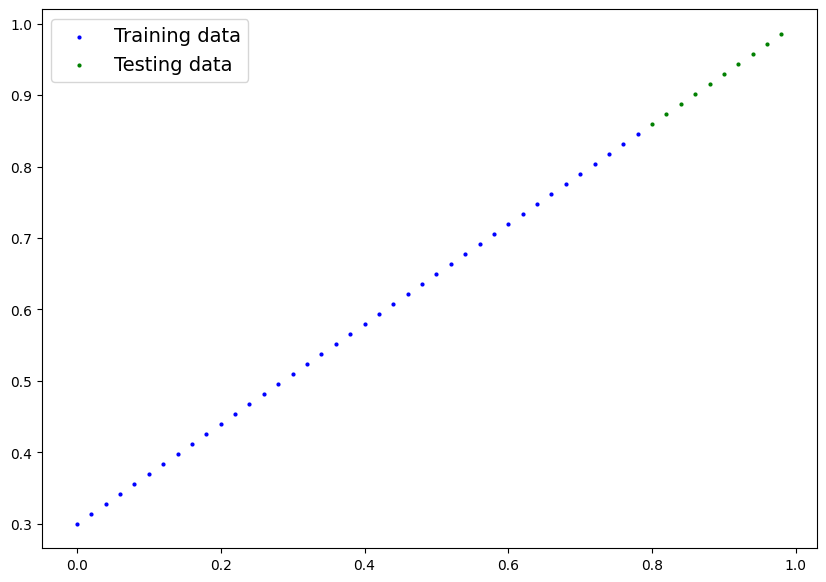

In [ ]:
plot_predictions()

In [ ]:
class LinearRegressionModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.weight = nn.Parameter(torch.randn(1, dtype=torch.float), requires_grad=True)
    self.bias = nn.Parameter(torch.randn(1, dtype=torch.float), requires_grad=True)

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    return self.weight * x + self.bias

In [ ]:
torch.manual_seed(42)
model_0 = LinearRegressionModel()

In [ ]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [ ]:
model_0.state_dict()

OrderedDict([('weight', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [ ]:
with torch.inference_mode():
  y_preds = model_0(X_test)

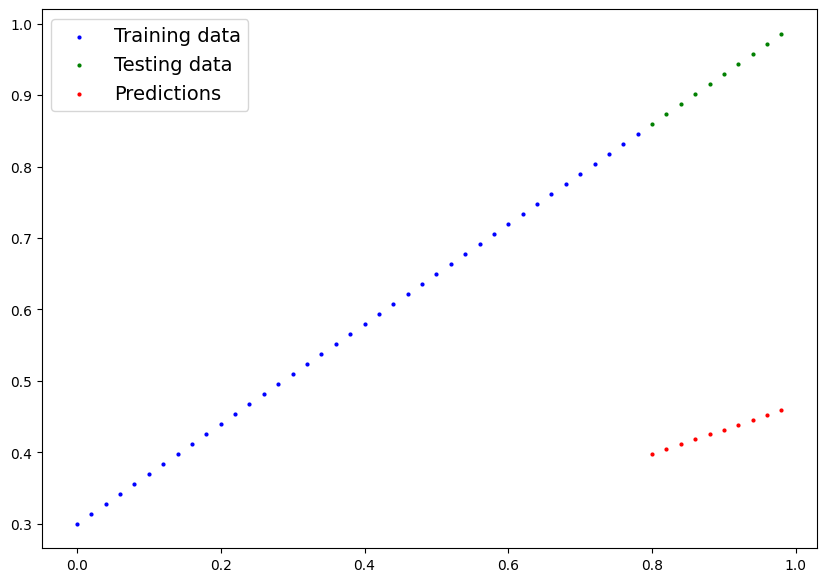

In [ ]:
plot_predictions(predictions=y_preds)

In [ ]:
y_test - y_preds

tensor([0.4618, 0.4691, 0.4764, 0.4836, 0.4909, 0.4982, 0.5054, 0.5127, 0.5200,
        0.5272])

In [ ]:
y_test[0] - y_preds[0]

tensor(0.4618)

In [ ]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.0001)

In [ ]:
print(X_train.shape)
print(y_train.shape)
print(y_preds.shape)


torch.Size([40])
torch.Size([40])
torch.Size([10])


In [ ]:
torch.manual_seed(42)

epochs = 10000
for epoch in range(epochs):
  # Training
  model_0.train()
  y_pred = model_0(X_train)
  loss = loss_fn(y_pred, y_train)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  # Testing
  model_0.eval()
  with torch.inference_mode():
    test_pred = model_0(X_test)
    test_loss = loss_fn(test_pred, y_test)
    if epoch % 10 == 0:
      print(f"Epoch: {epoch}, loss: {loss}, Test loss: {test_loss}")
      print(model_0.state_dict())

Epoch: 0, loss: 0.020904887467622757, Test loss: 0.04887700080871582
OrderedDict({'weight': tensor([0.5960]), 'bias': tensor([0.3437])})
Epoch: 10, loss: 0.0208705123513937, Test loss: 0.048790913075208664
OrderedDict({'weight': tensor([0.5962]), 'bias': tensor([0.3436])})
Epoch: 20, loss: 0.020836176350712776, Test loss: 0.04871169477701187
OrderedDict({'weight': tensor([0.5964]), 'bias': tensor([0.3435])})
Epoch: 30, loss: 0.020801812410354614, Test loss: 0.04863587021827698
OrderedDict({'weight': tensor([0.5965]), 'bias': tensor([0.3435])})
Epoch: 40, loss: 0.020767485722899437, Test loss: 0.04855319857597351
OrderedDict({'weight': tensor([0.5967]), 'bias': tensor([0.3434])})
Epoch: 50, loss: 0.020733091980218887, Test loss: 0.04847050458192825
OrderedDict({'weight': tensor([0.5969]), 'bias': tensor([0.3433])})
Epoch: 60, loss: 0.020698759704828262, Test loss: 0.04839129000902176
OrderedDict({'weight': tensor([0.5970]), 'bias': tensor([0.3432])})
Epoch: 70, loss: 0.02066435292363166

In [ ]:
with torch.inference_mode():
  y_preds_new = model_0(X_test)

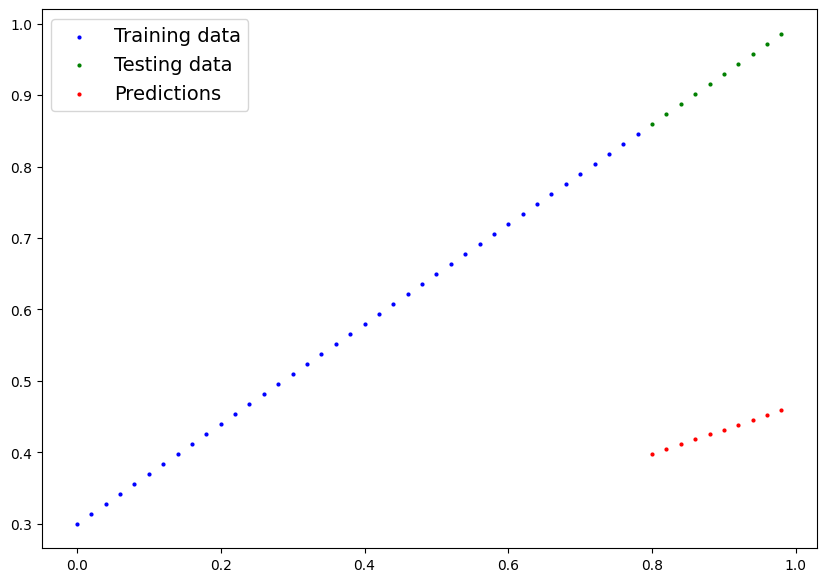

In [ ]:
plot_predictions(predictions=y_preds)

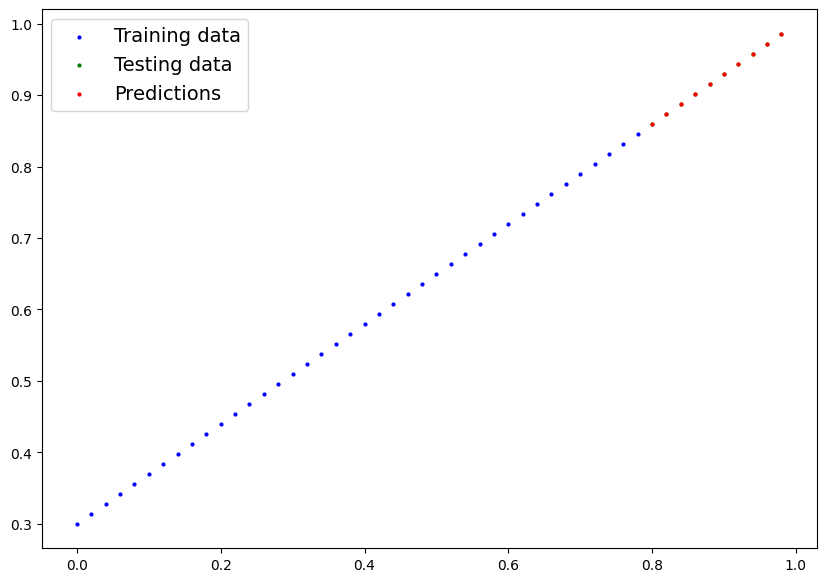

In [ ]:
plot_predictions(predictions=y_preds_new)

In [ ]:
from pathlib import Path
# Creating a models dict
MODEL_PATH = Path('models')
MODEL_PATH.mkdir(parents=True, exist_ok=True)
# Creating a path to it
MODEL_NAME = "01_pytorch_workflow_model_0"
MODEL_NAME_PATH = MODEL_PATH / MODEL_NAME
# Save model state dict
torch.save(obj=model_0.state_dict(), f=MODEL_NAME_PATH)


In [ ]:
# Loading a model
loaded_model_0 = LinearRegressionModel()
loaded_model_0.load_state_dict(torch.load(f=MODEL_NAME_PATH))

<All keys matched successfully>

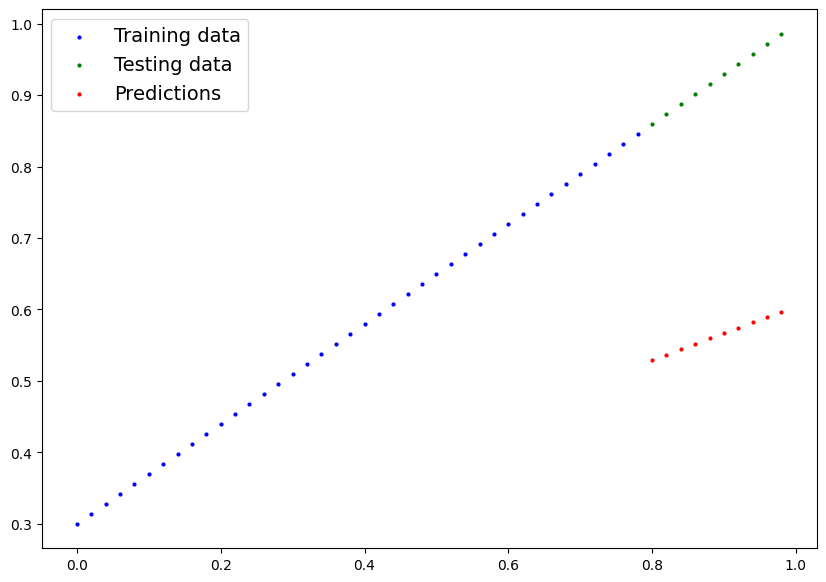

In [ ]:
loaded_model_0.eval()
with torch.inference_mode():
  loaded_preds = loaded_model_0(X_test)
plot_predictions(predictions=loaded_preds)

In [ ]:
import torch
from torch import nn
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

In [ ]:
torch.manual_seed(42)

weight = 0.8
bias = 0.2

start = 0
end = 1
step = 0.02

X = torch.arange(start, end, step).unsqueeze(1)
y = weight * X + bias
X[:10]

tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800]])

In [ ]:
split = int(0.8 * len(X))
X_train, y_train = X[:split], y[:split]
X_test, y_test = X[split:], y[split:]
len(X_train), len(y_train), len(X_test), len(y_test)

(40, 40, 10, 10)

In [ ]:
torch.manual_seed(42)

class LinearRegressionModelV2(nn.Module):
  def __init__(self):
    super().__init__()

    self.linear_layer = nn.Linear(in_features=1,
                                  out_features=1)
  def forward(self, X: torch.Tensor) -> torch.Tensor:
    return self.linear_layer(X)

model_1 = LinearRegressionModelV2().to(device)
model_1, model_1.state_dict()

(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]], device='cuda:0')),
              ('linear_layer.bias', tensor([0.8300], device='cuda:0'))]))

In [ ]:
loss_fn = nn.L1Loss()
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.01)

In [ ]:
X_train = X_train.to(device)
y_train = y_train.to(device)
X_test = X_test.to(device)
y_test = y_test.to(device)

epochs = 200
for epoch in range(epochs):

  # Training
  model_1.train()
  y_preds = model_1(X_train)
  loss = loss_fn(y_preds, y_train)
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()

  # Testing
  model_1.eval()
  with torch.inference_mode():
    test_preds = model_1(X_test)

    test_loss = loss_fn(test_preds, y_test)

  if epoch % 10 == 0:
    print(f"State Dict: {model_1.state_dict()}, Loss: {loss}, Test Loss: {test_loss}")



State Dict: OrderedDict({'linear_layer.weight': tensor([[0.7987]], device='cuda:0'), 'linear_layer.bias': tensor([0.2095], device='cuda:0')}), Loss: 0.0025308155454695225, Test Loss: 0.008325040340423584
State Dict: OrderedDict({'linear_layer.weight': tensor([[0.7987]], device='cuda:0'), 'linear_layer.bias': tensor([0.2095], device='cuda:0')}), Loss: 0.0025308155454695225, Test Loss: 0.008325040340423584
State Dict: OrderedDict({'linear_layer.weight': tensor([[0.7987]], device='cuda:0'), 'linear_layer.bias': tensor([0.2095], device='cuda:0')}), Loss: 0.0025308155454695225, Test Loss: 0.008325040340423584
State Dict: OrderedDict({'linear_layer.weight': tensor([[0.7987]], device='cuda:0'), 'linear_layer.bias': tensor([0.2095], device='cuda:0')}), Loss: 0.0025308155454695225, Test Loss: 0.008325040340423584
State Dict: OrderedDict({'linear_layer.weight': tensor([[0.7987]], device='cuda:0'), 'linear_layer.bias': tensor([0.2095], device='cuda:0')}), Loss: 0.0025308155454695225, Test Loss: 0

In [ ]:
def plot_predictions(train_data=X_train.cpu(),
                     train_labels=y_train.cpu(),
                     test_data=X_test.cpu(),
                     test_labels=y_test.cpu(),
                     predictions=None):
  """
  Plots training data, test data and compares predictions.
  """
  plt.figure(figsize=(10, 7))

  # Plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")

  # Plot test data in green
  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")

  if predictions is not None:
    # Plot the predictions in red (predictions were made on the test data)
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

  # Show the legend
  plt.legend(prop={"size": 14});

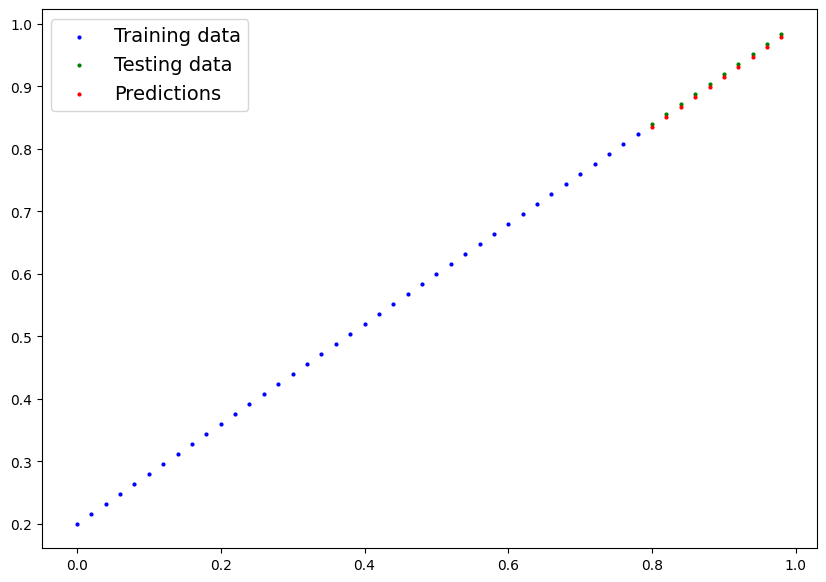

In [ ]:
model_1.eval()
with torch.inference_mode():
  test_preds = model_1(X_test)
plot_predictions(predictions=test_preds.cpu())

In [ ]:
weight, bias

(0.8, 0.2)

In [ ]:
from pathlib import Path

# Saving a Model
MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

MODEL_NAME = "01_pytorch_workflow_model_01"
MODEL_PATH_NAME = MODEL_PATH / MODEL_NAME

torch.save(obj=model_1.state_dict(), f=MODEL_PATH_NAME)

In [ ]:
# Loading a Model
loaded_model_01 = LinearRegressionModelV2()
loaded_model_01.load_state_dict(torch.load(f=MODEL_PATH_NAME))

<All keys matched successfully>

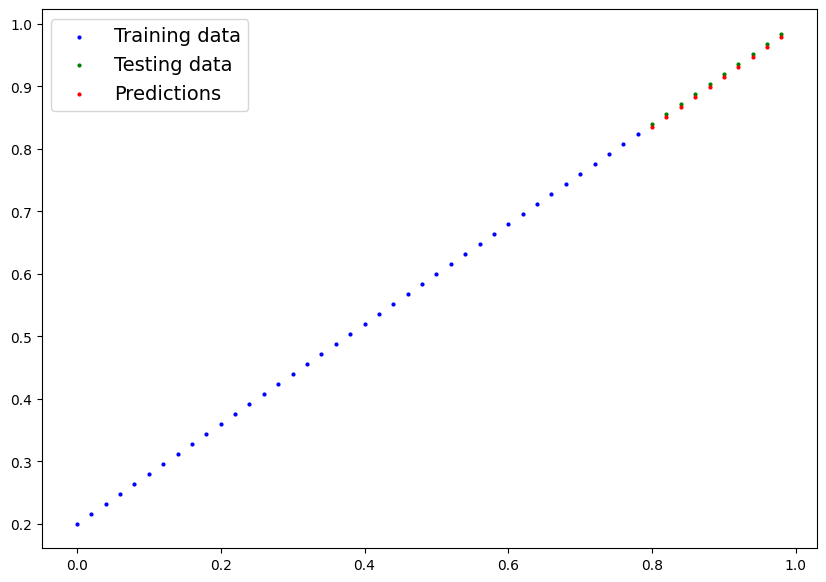

In [ ]:
loaded_model_01.eval().to(device)
with torch.inference_mode():
  loaded_preds = loaded_model_01(X_test)

plot_predictions(predictions=loaded_preds.cpu())

In [ ]:
|